In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
stellar_params = pd.read_csv('./take_two_stellar_params_CTL.csv')
print(stellar_params)

toi_params = pd.read_csv('./TOI_Mar2025_1pt5to4_R_detected_real_only.csv')
toi_params = toi_params[toi_params['pl_rade'] >= 1.8]
toi_params = toi_params[toi_params['pl_rade'] <= 4.0]
toi_params = toi_params[toi_params['pl_orbper'] >= .6]
toi_params = toi_params[toi_params['pl_orbper'] <= 25]
toi_params = toi_params[toi_params['Stellar Magnitude'] <= 13]  # drop faint tail (Tmag>13): no CTL stars exist there

print(toi_params)

            id  sector_length     tmag       RAD   MASS       teff    teff_bin
0     51988363            2.0   9.5563  1.182280  1.020  5720.0000  5500-6000K
1    172076858            4.0  10.5804  0.813724  0.880  5186.0000  5000-5500K
2    140067408            2.0   9.8744  0.973123  1.000  5656.0000  5500-6000K
3    284566637            5.0  10.7167  1.218320  1.131  6062.8799  6000-6500K
4     11148069            4.0  10.0391  0.735781  0.840  5044.0000  5000-5500K
..         ...            ...      ...       ...    ...        ...         ...
870  293281733            3.0  10.6622  1.051890  1.146  6099.4102  6000-6500K
871  268529531            2.0  11.8677  0.897275  1.050  5843.0000  5500-6000K
872  287192872           11.0  10.4689  0.840756  0.975  5541.0000  5500-6000K
873  140894354           24.0   7.7105  1.254550  1.100  5971.4302  5500-6000K
874  167720952           23.0  10.9269  0.802446  0.950  5458.0000  5000-5500K

[875 rows x 7 columns]
         TOI            TIC 

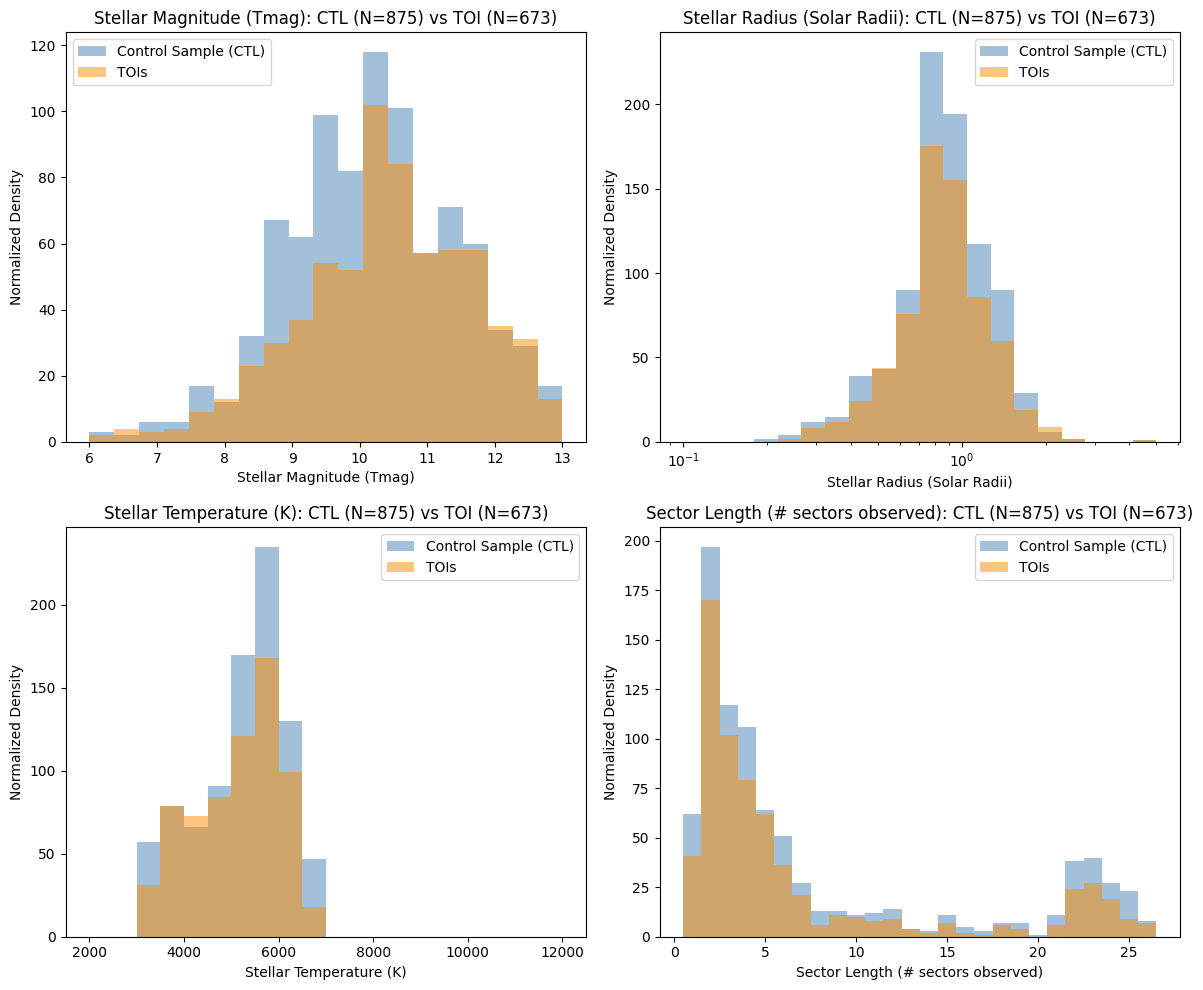

In [3]:
# Compare stellar_params (control sample) vs toi_params (detected TOIs) distributions.
# Bin edges for RAD/tmag/teff match the grid defined in TOI_CTL.ipynb
# (cat.set_xbins/set_ybins/set_zbins): RAD is log-spaced, Tmag and Teff are linear.
# sector_length isn't in toi_params directly -- pull it from TOI_sector_results.csv
toi_sectors = pd.read_csv('./TOI_sector_results.csv')
toi_params_with_sectors = toi_params.merge(toi_sectors[['toi', 'sector_length']], on='toi', how='left')

rad_bins = np.geomspace(0.1, 5, 21)      # matches cat.set_xbins(0.1, 5, 21) in TOI_CTL.ipynb
tmag_bins = np.linspace(6, 13, 20)       # matches cat.set_ybins(6, 13, 20, Log=False)
teff_bins = np.linspace(2000, 12000, 21) # matches cat.set_zbins(2000, 12000, 21, Log=False)

comparisons = [
    ('tmag', 'Stellar Magnitude', 'Stellar Magnitude (Tmag)', tmag_bins),
    ('RAD', 'Stellar Radius', 'Stellar Radius (Solar Radii)', rad_bins),
    ('teff', 'Stellar Temperature', 'Stellar Temperature (K)', teff_bins),
    ('sector_length', 'sector_length', 'Sector Length (# sectors observed)', None),  # integer bins, set below
]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (ctl_col, toi_col, label, bins) in zip(axes.flat, comparisons):
    ctl_vals = stellar_params[ctl_col].dropna()
    toi_vals = toi_params_with_sectors[toi_col].dropna()

    if bins is None:
        # sector_length is a small integer count -- one bin per integer value
        lo = int(min(ctl_vals.min(), toi_vals.min()))
        hi = int(max(ctl_vals.max(), toi_vals.max()))
        bins = np.arange(lo, hi + 2) - 0.5  # bin edges centered on each integer

    ax.hist(ctl_vals, bins=bins, alpha=0.5, density=False, label='Control Sample (CTL)', color='steelblue')
    ax.hist(toi_vals, bins=bins, alpha=0.5, density=False, label='TOIs', color='darkorange')

    if ctl_col == 'RAD':
        ax.set_xscale('log')

    ax.set_xlabel(label)
    ax.set_ylabel('Normalized Density')
    ax.set_title(f'{label}: CTL (N={len(ctl_vals)}) vs TOI (N={len(toi_vals)})')
    ax.legend()

plt.tight_layout()
plt.show()


1
reuse already-run = 600   NEW to run = 73   FINAL = 673   (TOI = 673)
already-run CTLs dropped (over-dense cells) = 275

KS p-value (final matched CTL vs TOI):
  tmag           0.952
  RAD            0.605
  sector_length  0.516
  teff           0.164   (not matched on)

saved: new_CTLs_to_run_injrec_rebalanced.csv  and  rebalanced_matched_CTL_sample.csv


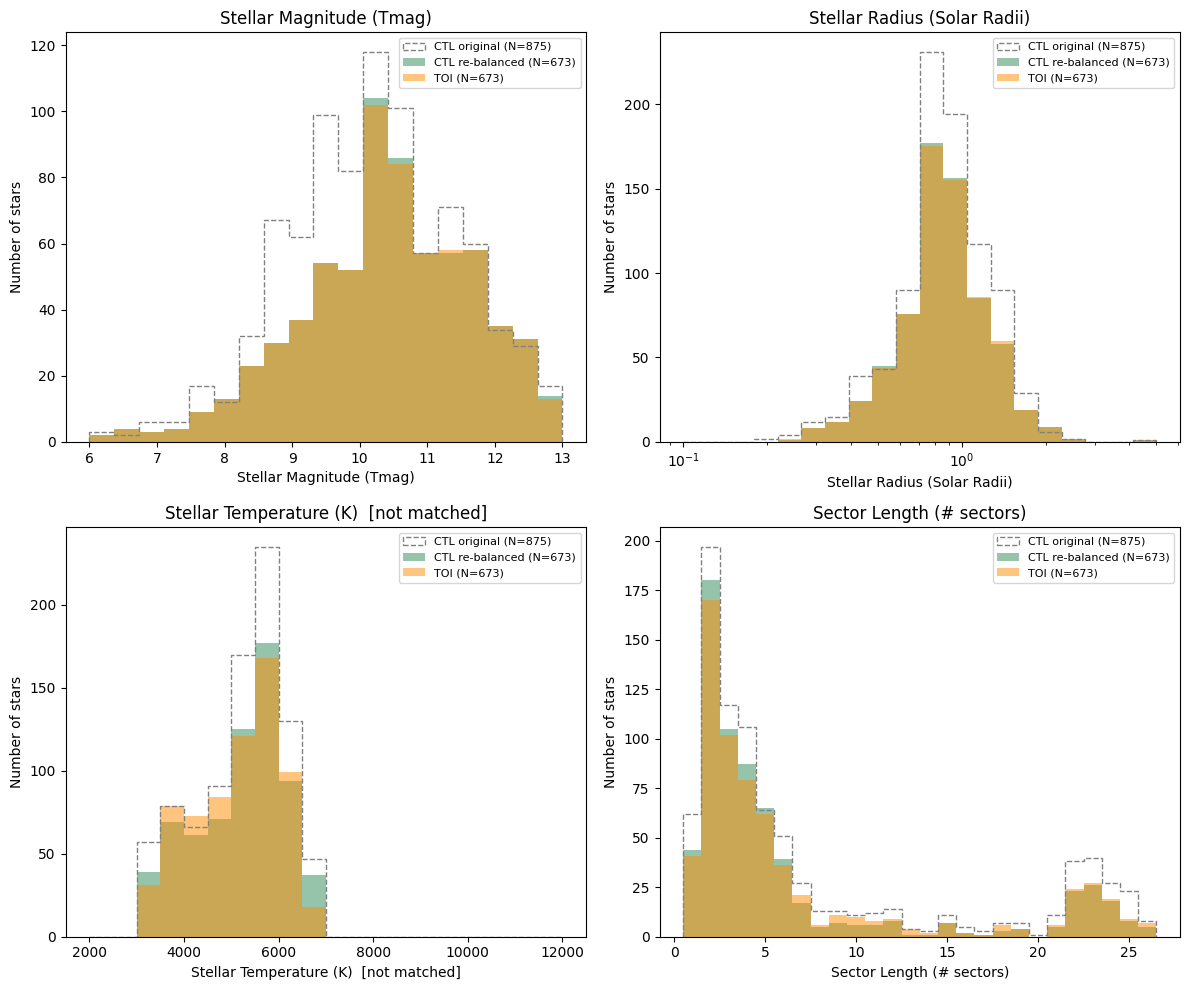

In [4]:
# ===========================================================================
# GOAL
# ---------------------------------------------------------------------------
# The CTL (control) sample and the TOI sample were originally drawn to have the
# same stellar-property distributions. After we cut the TOI list, TOI's
# distributions shifted, so the two no longer match. This cell rebuilds a CTL
# sample that matches TOI again, subject to two practical constraints:
#
#   (1) The final CTL must be AT LEAST as large as TOI. So we cannot fix the
#       mismatch by removal alone (that shrinks CTL too much) -- we must ADD
#       some new CTL stars where the existing sample is too sparse.
#   (2) Every NEW CTL star triggers a slow injection/recovery run, so we want
#       to add as FEW new stars as possible and REUSE the already-run ones.
#
# MATCHING STRATEGY
#   - Match (tmag, RAD) JOINTLY, using the same bin grid as TOI_CTL.ipynb.
#   - Match sector_length as a SEPARATE 1-D marginal (it fragments the joint
#     grid too much to include as a third joint axis).
#   - Work only inside the TOI_CTL bin domain (tmag 6-13, RAD 0.1-5). Stars
#     outside it are ignored, exactly as TOI_CTL.ipynb does. (The faint tail
#     tmag>13 was already removed from toi_params in the earlier cell.)
# ===========================================================================
from collections import Counter
from scipy.stats import ks_2samp

# ---------------------------------------------------------------------------
# STEP 1 -- Load the pool of candidate CTL stars we are allowed to draw from.
# CTL_10x_with_sectors.csv is the 10x-oversampled matched CTL pool; crucially it
# already has sector_length computed, so any star we pick from it is ready to
# use without a fresh sector lookup. The 875 already-run CTLs are a subset of it.
# ---------------------------------------------------------------------------
pool = pd.read_csv('./CTL_10x_with_sectors.csv')
pool['tic'] = pool['tic'].str.replace('TIC ', '', regex=False).astype(int)  # "TIC 12345" -> 12345
pool = pool.rename(columns={'st_tmag': 'tmag', 'st_rad': 'RAD', 'st_teff': 'teff', 'st_mass': 'MASS'})

# Flag which pool stars we have ALREADY run inj/rec on (free to reuse) vs which
# would be NEW (expensive). stellar_params['id'] holds the 875 already-run TICs.
pool['already_run'] = pool['tic'].isin(stellar_params['id'])
pool_new = pool[~pool['already_run']].copy()   # candidate NEW stars only

# ---------------------------------------------------------------------------
# STEP 2 -- Put the three samples on a common column schema (tic, tmag, RAD,
# teff, MASS, sector_length) so we can bin and compare them the same way:
#   existing = the 875 CTLs already run       (reuse these first)
#   pool_new = candidate new CTLs             (add only if needed)
#   toi      = the TOI sample we want to match
# ---------------------------------------------------------------------------
existing = stellar_params.rename(columns={'id': 'tic'})
toi = toi_params_with_sectors.rename(columns={
    'Stellar Magnitude': 'tmag', 'Stellar Radius': 'RAD', 'Stellar Temperature': 'teff'
})[['tmag', 'RAD', 'teff', 'sector_length']].dropna()

# ---------------------------------------------------------------------------
# STEP 3 -- Define the matching grid. tmag and RAD reuse the exact bin edges
# generated by TOI_CTL.ipynb (tmag_bins / rad_bins were built in the cell above).
# in_domain() marks stars that fall inside the grid; anything outside is dropped
# from the match (TOI_CTL's convention: "values outside the range are not used").
# ---------------------------------------------------------------------------
match_tmag_bins = tmag_bins   # np.linspace(6, 13, 20)   <- TOI_CTL cat.set_ybins(6,13,20)
match_rad_bins = rad_bins     # np.geomspace(0.1, 5, 21) <- TOI_CTL cat.set_xbins(0.1,5,21)

def in_domain(d):
    return (d.tmag >= 6) & (d.tmag <= 13) & (d.RAD >= 0.1) & (d.RAD <= 5)

# rc_cell = the (tmag_bin_index, RAD_bin_index) a star lands in -> its 2-D cell.
# np.digitize with the interior edges [1:-1] returns one index per star; zipping
# the two gives a hashable (i, j) key we can group and count by.
def rc_cell(d):
    return list(zip(np.digitize(d.tmag, match_tmag_bins[1:-1]),
                    np.digitize(d.RAD,  match_rad_bins[1:-1])))

# Restrict each sample to the grid domain, drop rows missing any match variable,
# and tag every star with its (tmag, RAD) cell id.
toi_d = toi[in_domain(toi)].copy()
ex    = existing[in_domain(existing)].dropna(subset=['tmag', 'RAD', 'sector_length']).copy()
pn    = pool_new[in_domain(pool_new)].dropna(subset=['tmag', 'RAD', 'sector_length']).copy()
toi_d['rc'] = rc_cell(toi_d)
ex['rc']    = rc_cell(ex)
pn['rc']    = rc_cell(pn)

# ---------------------------------------------------------------------------
# STEP 4 -- Build the TARGET histograms: how many stars the final CTL should
# have in each (tmag, RAD) cell, and in each sector_length value.
#
# We want the final CTL to (a) have TOI's SHAPE and (b) total >= len(TOI). TOI's
# in-domain count can be slightly below len(TOI), so we scale the TOI histogram
# up to exactly T = len(TOI) stars while preserving its shape.
#
# largest_remainder() distributes T stars across cells in proportion to TOI's
# counts, rounding so the per-cell integers sum to EXACTLY T. (Rounding every
# cell up instead would overshoot T and force us to add extra new stars.)
# ---------------------------------------------------------------------------
T = len(toi)   # the size the final CTL must meet or beat (= current TOI size)

def largest_remainder(counts, total):
    keys = list(counts)
    raw = np.array([counts[k] for k in keys], float)
    raw = raw / raw.sum() * total          # ideal (fractional) count per key
    floor = np.floor(raw).astype(int)      # start with the floors...
    # ...then hand the leftover stars to the keys with the largest fractions,
    # so the integer counts add up to exactly `total`.
    for i in np.argsort(-(raw - floor))[:total - floor.sum()]:
        floor[i] += 1
    return {k: int(v) for k, v in zip(keys, floor)}

rc_target  = largest_remainder(Counter(toi_d['rc']), T)                          # (tmag,RAD) joint target
sec_target = largest_remainder(Counter(toi_d['sector_length'].astype(int)), T)   # sector_length marginal target

# ---------------------------------------------------------------------------
# STEP 5 -- Fill each (tmag, RAD) cell up to its target count.
#
# For each cell we need `need` stars. We take ALREADY-RUN stars first (free),
# then top up with NEW pool stars only if the cell is still short. That reuses
# as many existing stars as possible and minimizes new inj/rec runs.
#
# WHICH stars we pick within a cell is steered by the sector_length marginal:
# sec_have counts how many of each sector we've taken so far, and sec_deficit()
# says how many more of a given sector we still want. Sorting a cell's candidates
# by sector_deficit (descending) means we preferentially grab stars whose sector
# is still under-represented -- this pulls the sector_length distribution toward
# its target while we fill the (tmag, RAD) grid.
# ---------------------------------------------------------------------------
sec_have = Counter()
def sec_deficit(s):
    return sec_target.get(int(s), 0) - sec_have.get(int(s), 0)

reuse_rows, new_rows = [], []
ex_by = {c: g for c, g in ex.groupby('rc')}   # already-run stars, grouped by cell
pn_by = {c: g for c, g in pn.groupby('rc')}   # new candidate stars, grouped by cell

for c, need in rc_target.items():
    picked = 0

    # (a) fill from already-run stars first, preferring under-filled sectors
    if c in ex_by:
        take = ex_by[c].assign(_d=ex_by[c]['sector_length'].map(sec_deficit)) \
                       .sort_values('_d', ascending=False).head(need)
        for s in take['sector_length']:
            sec_have[int(s)] += 1
        reuse_rows.append(take)
        picked = len(take)

    # (b) if the cell is still short, add NEW stars, again preferring the
    #     sectors we still need most
    short = need - picked
    if short > 0 and c in pn_by:
        take = pn_by[c].assign(_d=pn_by[c]['sector_length'].map(sec_deficit)) \
                       .sort_values('_d', ascending=False).head(short)
        for s in take['sector_length']:
            sec_have[int(s)] += 1
        new_rows.append(take)

R = pd.concat(reuse_rows, ignore_index=True) if reuse_rows else ex.iloc[:0]   # reused already-run stars
N = pd.concat(new_rows,   ignore_index=True) if new_rows   else pn.iloc[:0]   # brand-new stars to run

# ---------------------------------------------------------------------------
# STEP 6 -- Safety top-up. A cell can end up short if neither the existing nor
# the pool stars could supply its target. If the grand total is below T, pull a
# few more NEW stars from the leftover pool (still steering by sector deficit)
# so the final sample is robustly >= T.
# ---------------------------------------------------------------------------
deficit = T - (len(R) + len(N))
if deficit > 0:
    leftover = pn[~pn['tic'].isin(N['tic'])].copy()
    leftover = leftover.assign(_d=leftover['sector_length'].map(sec_deficit)) \
                       .sort_values('_d', ascending=False).head(deficit)
    N = pd.concat([N, leftover], ignore_index=True)

print(deficit)

# ---------------------------------------------------------------------------
# STEP 7 -- Assemble the final matched CTL, tagging each star's origin so you
# can tell which ones still need inj/rec ('new') vs which are done ('already_run').
# MASS is included here (both ex/pool already carry it) so it flows into both
# saved CSVs below.
# ---------------------------------------------------------------------------
cols = ['tic', 'tmag', 'RAD', 'teff', 'MASS', 'sector_length']
matched_ctl = pd.concat([R[cols].assign(source='already_run'),
                         N[cols].assign(source='new')], ignore_index=True)

# ---------------------------------------------------------------------------
# STEP 8 -- Report the outcome and check the match with 2-sample KS tests
# (higher p-value = the two distributions are more consistent). teff is printed
# as a diagnostic only -- we did NOT match on it, so it should improve indirectly
# through its correlation with tmag/RAD but isn't forced.
# ---------------------------------------------------------------------------
print(f"reuse already-run = {len(R)}   NEW to run = {len(N)}   FINAL = {len(matched_ctl)}   (TOI = {T})")
print(f"already-run CTLs dropped (over-dense cells) = {len(existing) - len(R)}")
print("\nKS p-value (final matched CTL vs TOI):")
for col in ['tmag', 'RAD', 'sector_length', 'teff']:
    tag = '' if col != 'teff' else '   (not matched on)'
    print(f"  {col:14s} {ks_2samp(matched_ctl[col], toi[col]).pvalue:.3f}{tag}")

# ---------------------------------------------------------------------------
# STEP 9 -- Save the two deliverables:
#   new_CTLs_to_run_injrec_rebalanced.csv = ONLY the new stars -> your inj/rec to-do list
#   rebalanced_matched_CTL_sample.csv     = the full matched CTL (with source tags)
# ---------------------------------------------------------------------------
N[cols].to_csv('./new_CTLs_to_run_injrec_rebalanced.csv', index=False)
matched_ctl.to_csv('./rebalanced_matched_CTL_sample.csv', index=False)
print("\nsaved: new_CTLs_to_run_injrec_rebalanced.csv  and  rebalanced_matched_CTL_sample.csv")

# ---------------------------------------------------------------------------
# STEP 10 -- Visual check. For each variable, overlay three histograms (raw
# counts): the original CTL (dashed outline), the re-balanced CTL (green), and
# TOI (orange). The green and orange should now sit on top of each other for
# tmag / RAD / sector_length; teff should be close as a byproduct.
# ---------------------------------------------------------------------------
panels = [
    ('tmag', 'Stellar Magnitude', 'Stellar Magnitude (Tmag)', tmag_bins),
    ('RAD', 'Stellar Radius', 'Stellar Radius (Solar Radii)', rad_bins),
    ('teff', 'Stellar Temperature', 'Stellar Temperature (K)  [not matched]', teff_bins),
    ('sector_length', 'sector_length', 'Sector Length (# sectors)', None),
]
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (mc_col, toi_col, label, bins) in zip(axes.flat, panels):
    orig = stellar_params[mc_col].dropna()          # original CTL (875)
    fin  = matched_ctl[mc_col].dropna()             # re-balanced CTL
    toiv = toi_params_with_sectors[toi_col].dropna()  # TOI
    if bins is None:  # sector_length: one bin per integer count
        lo = int(min(orig.min(), toiv.min())); hi = int(max(orig.max(), toiv.max()))
        bins = np.arange(lo, hi + 2) - 0.5
    ax.hist(orig, bins=bins, density=False, histtype='step', linestyle='--',
            color='gray', label=f'CTL original (N={len(orig)})')
    ax.hist(fin, bins=bins, alpha=0.5, density=False, color='seagreen',
            label=f'CTL re-balanced (N={len(fin)})')
    ax.hist(toiv, bins=bins, alpha=0.5, density=False, color='darkorange',
            label=f'TOI (N={len(toiv)})')
    if mc_col == 'RAD':
        ax.set_xscale('log')
    ax.set_xlabel(label); ax.set_ylabel('Number of stars')
    ax.set_title(label); ax.legend(fontsize=8)
plt.tight_layout()
plt.show()